# Tópico 10 - Transformada de Laplace

## Visão Geral e Objetivos
Neste notebook, investigamos a **Transformada de Laplace** e sua aplicação na análise de sinais e sistemas contínuos no plano complexo $s$. Os principais objetivos são:
1. **Conceituação da Variável Complexa $s$**: Compreender a composição $s = \sigma + j\omega$, em que $\sigma$ representa a taxa de atenuação/crescimento exponencial (em $\text{Np/s}$ ou $\text{rad/s}$) e $\omega$ representa a frequência angular de oscilação (em $\text{rad/s}$).
2. **Transformadas de Sinais Elementares**: Avaliar analítica e numericamente as transformadas de Laplace bilaterais/unilaterais para sinais fundamentais como o degrau unitário $u(t)$, a exponencial decrescente $e^{-at}u(t)$ e a senoide amortecida $e^{-at}\cos(\omega_0 t)u(t)$.
3. **Mapeamento no Plano-$s$ e Respostas Temporais**: Relacionar a posição dos polos no plano-$s$ ($\text{Re}\{s\} = \sigma$ e $\text{Im}\{s\} = \omega$) com a dinâmica da resposta temporal (estabilidade, amortecimento e oscilação).
4. **Gerenciamento de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação para inclusão no relatório técnico.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Exemplo Analítico e Simulação de Sinais Elementares

A Transformada de Laplace de um sinal de tempo contínuo $x(t)$ é definida por:
$$X(s) = \int_{-\infty}^{+\infty} x(t) e^{-st} \, dt, \quad s = \sigma + j\omega$$

Abaixo, analisamos dois exemplos analíticos elementares:
1. **Exponencial Decrescente**: $x_1(t) = e^{-2t} u(t) \stackrel{\mathcal{L}}{\longleftrightarrow} X_1(s) = \frac{1}{s + 2}, \quad \text{ROC: } \text{Re}\{s\} > -2$
2. **Senoide Amortecida**: $x_2(t) = e^{-t} \cos(4\pi t) u(t) \stackrel{\mathcal{L}}{\longleftrightarrow} X_2(s) = \frac{s + 1}{(s + 1)^2 + (4\pi)^2}, \quad \text{ROC: } \text{Re}\{s\} > -1$

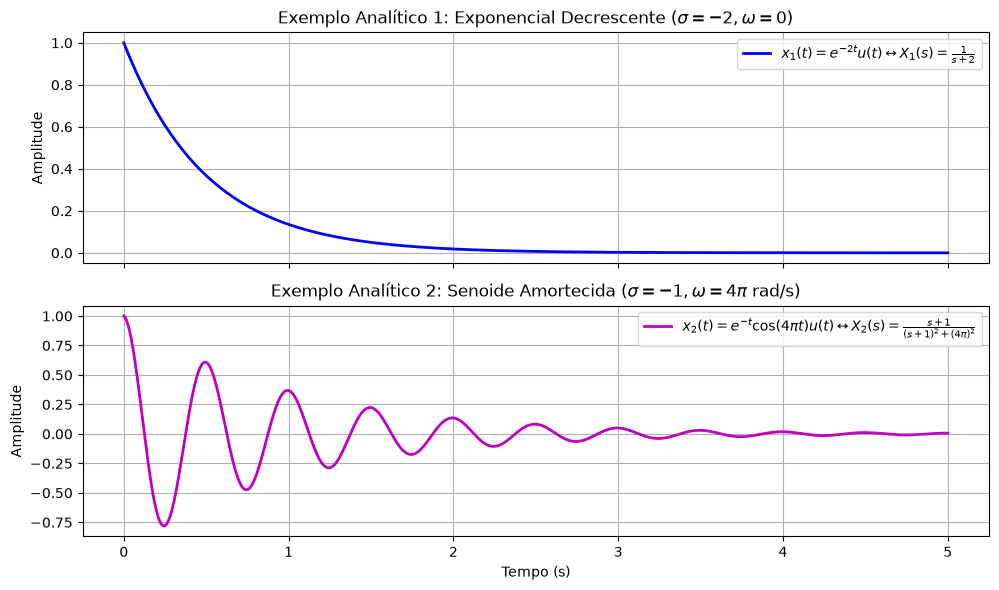

In [2]:
# Vetor temporal continuo de 0 a 5 segundos
t = np.linspace(0, 5, 1000)

# 1. Exemplo 1: Exponencial Decrescente x1(t) = exp(-2t) u(t)
# Sistema equivalente H1(s) = 1 / (s + 2)
sistema1 = signal.lti([1.0], [1.0, 2.0])
t1, x1 = signal.impulse(sistema1, T=t)

# 2. Exemplo 2: Senoide Amortecida x2(t) = exp(-t) * cos(4*pi*t) u(t)
# Sistema equivalente H2(s) = (s + 1) / ((s + 1)^2 + (4*pi)^2) = (s + 1) / (s^2 + 2s + 1 + 16*pi^2)
a = 1.0
w0 = 4.0 * np.pi
num2 = [1.0, a]
den2 = [1.0, 2.0 * a, a**2 + w0**2]
sistema2 = signal.lti(num2, den2)
t2, x2 = signal.impulse(sistema2, T=t)

# Plotagem das respostas temporais dos exemplos analíticos
fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Subplot 1: Exponencial Decrescente
ax1.plot(t1, x1, 'b-', linewidth=2, label=r'$x_1(t) = e^{-2t} u(t) \leftrightarrow X_1(s) = \frac{1}{s+2}$')
ax1.set_title(r'Exemplo Analítico 1: Exponencial Decrescente ($\sigma = -2, \omega = 0$)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)
ax1.legend(loc='upper right')

# Subplot 2: Senoide Amortecida
ax2.plot(t2, x2, 'm-', linewidth=2, label=r'$x_2(t) = e^{-t}\cos(4\pi t) u(t) \leftrightarrow X_2(s) = \frac{s+1}{(s+1)^2 + (4\pi)^2}$')
ax2.set_title(r'Exemplo Analítico 2: Senoide Amortecida ($\sigma = -1, \omega = 4\pi\text{ rad/s}$)')
ax2.set_xlabel('Tempo (s)')
ax2.set_ylabel('Amplitude')
ax2.grid(True)
ax2.legend(loc='upper right')

plt.tight_layout()
fig1.savefig("grafico_exemplos_laplace.png")
plt.show()

## 2. Relação entre a Posição dos Polos no Plano-$s$ e a Resposta Temporal

A localização da variável complexa $s = \sigma + j\omega$ dita o comportamento dinâmico da resposta temporal $x(t) = e^{\sigma t} \cos(\omega t) u(t)$:
- **$\text{Re}\{s\} = \sigma < 0$ (Semiplano Esquerdo)**: O sinal exibe decaimento exponencial ($e^{-|\sigma| t} \rightarrow 0$), caracterizando estabilidade assintótica.
- **$\text{Re}\{s\} = \sigma = 0$ (Eixo Imaginário $j\omega$)**: O sinal mantém oscilação sustentada de amplitude constante.
- **$\text{Re}\{s\} = \sigma > 0$ (Semiplano Direito)**: O sinal exibe crescimento exponencial divergente ($e^{+\sigma t} \rightarrow \infty$), caracterizando instabilidade.
- **$\text{Im}\{s\} = \omega \neq 0$**: Introduz componente oscilatória de frequência $\omega\text{ rad/s}$.

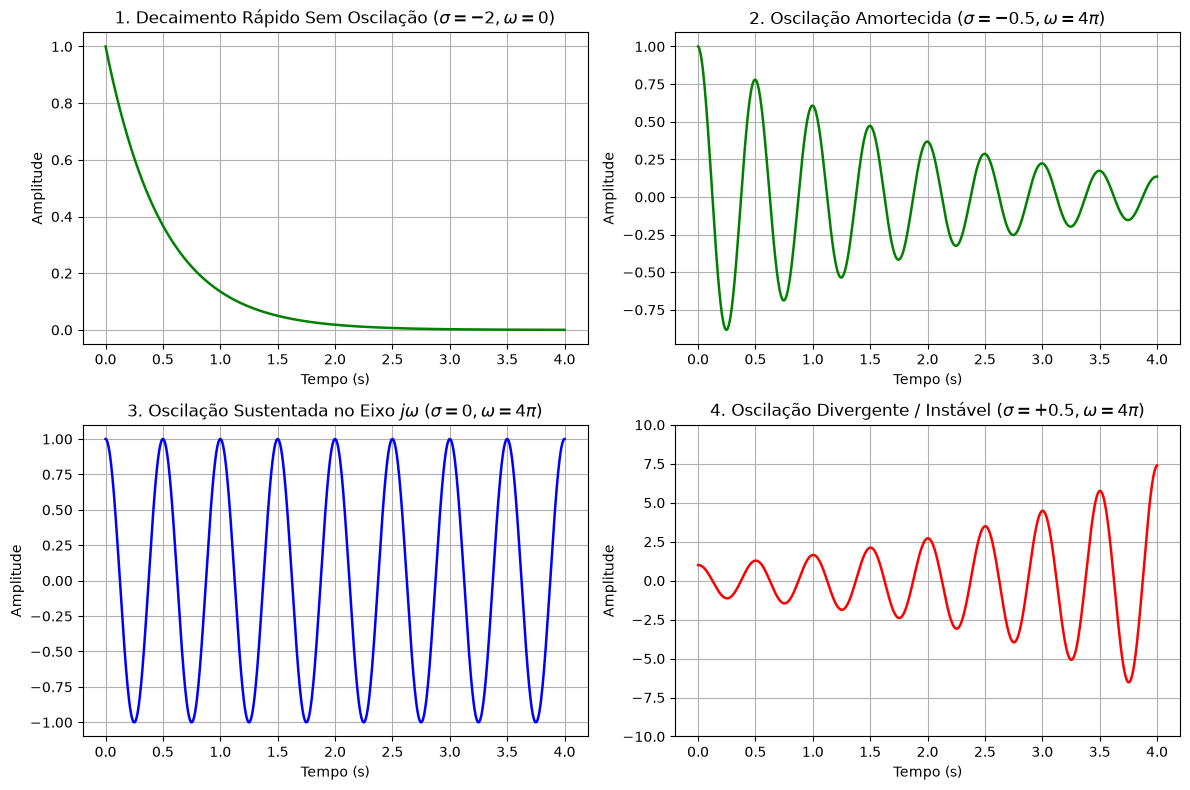

In [3]:
# Definição de 4 cenários de polos no plano-s: (sigma, omega, titulo)
cenarios_polos = [
    (-2.0, 0.0, r'1. Decaimento Rápido Sem Oscilação ($\sigma = -2, \omega = 0$)'),
    (-0.5, 4 * np.pi, r'2. Oscilação Amortecida ($\sigma = -0.5, \omega = 4\pi$)'),
    (0.0, 4 * np.pi, r'3. Oscilação Sustentada no Eixo $j\omega$ ($\sigma = 0, \omega = 4\pi$)'),
    (0.5, 4 * np.pi, r'4. Oscilação Divergente / Instável ($\sigma = +0.5, \omega = 4\pi$)')
]

t_sim = np.linspace(0, 4, 1000)

fig2, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()

for idx, (sigma, omega, titulo) in enumerate(cenarios_polos):
    # Resposta no tempo x(t) = exp(sigma * t) * cos(omega * t)
    x_t = np.exp(sigma * t_sim) * np.cos(omega * t_sim)
    
    cor = 'g' if sigma < 0 else ('b' if sigma == 0 else 'r')
    
    axs[idx].plot(t_sim, x_t, color=cor, linewidth=1.8)
    axs[idx].set_title(titulo)
    axs[idx].set_xlabel('Tempo (s)')
    axs[idx].set_ylabel('Amplitude')
    axs[idx].grid(True)
    if sigma > 0:
        axs[idx].set_ylim(-10, 10)

plt.tight_layout()
fig2.savefig("grafico_laplace_plano_s.png")
plt.show()

## 3. Síntese dos Resultados sobre a Transformada de Laplace
- **Significado da Variável $s$**: A variável complexa $s = \sigma + j\omega$ estende a análise de Fourier ($\sigma = 0$) para incluir amortecimento e crescimento exponencial através da componente real $\sigma$.
- **Mapeamento de Estabilidade**: Polos estritamente no semiplano esquerdo ($\sigma < 0$) garantem a convergência temporal do sinal, enquanto polos no semiplano direito ($\sigma > 0$) produzem respostas ilimitadas/instáveis.
- **Ponte com Controle e Automação**: A Transformada de Laplace converte equações diferenciais lineares em equações algébricas no domínio-$s$, permitindo avaliar a dinâmica de sistemas contínuos por meio da posição de seus polos e zeros.